In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)



In [3]:
try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart(2).csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

df.columns = df.columns.str.strip().str.lower()
df = df.drop_duplicates()

X = df.drop(columns=["target"])
y = df["target"].astype(int)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("\nFeatures:")
print(list(X.columns))

Dataset loaded successfully.
Dataset shape: (302, 14)

Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Training samples:", len(X_train_imputed))
print("Testing samples:", len(X_test_imputed))

Training samples: 241
Testing samples: 61


In [5]:
model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_imputed, y_train)

original_predictions = model.predict(X_test_imputed)

original_probabilities = model.predict_proba(
    X_test_imputed
)[:, 1]

baseline_accuracy = accuracy_score(
    y_test,
    original_predictions
)

baseline_f1 = f1_score(
    y_test,
    original_predictions,
    zero_division=0
)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline F1 Score:", round(baseline_f1, 4))

Baseline Accuracy: 0.7705
Baseline F1 Score: 0.7879


In [6]:
feature_importance = pd.DataFrame({
    "Feature": X_train_imputed.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(feature_importance)

top_features = feature_importance["Feature"].head(5).tolist()

print("Selected features for adversarial testing:")
print(top_features)

Feature Importance:


,Feature,Importance
2,cp,0.165958
7,thalach,0.121805
11,ca,0.115270
12,thal,0.095851
9,oldpeak,0.092243
0,age,0.083290
8,exang,0.075064
4,chol,0.072054
3,trestbps,0.067305
1,sex,0.041512


Selected features for adversarial testing:
['cp', 'thalach', 'ca', 'thal', 'oldpeak']


In [7]:
X_random = X_test_imputed.copy()

rng = np.random.default_rng(42)

perturbation_strength = 0.05

for column in X_random.columns:

    feature_std = X_train_imputed[column].std()

    noise = rng.normal(
        loc=0,
        scale=perturbation_strength * feature_std,
        size=len(X_random)
    )

    X_random[column] = X_random[column] + noise

# Generate predictions
random_predictions = model.predict(X_random)

random_accuracy = accuracy_score(
    y_test,
    random_predictions
)

random_f1 = f1_score(
    y_test,
    random_predictions,
    zero_division=0
)

print("Random Perturbation Accuracy:", round(random_accuracy, 4))
print("Random Perturbation F1:", round(random_f1, 4))

Random Perturbation Accuracy: 0.7705
Random Perturbation F1: 0.7879


In [8]:
X_percentage = X_test_imputed.copy()

percentage_change = 0.05

for feature in top_features:

    X_percentage[feature] = (
        X_percentage[feature] *
        (1 + percentage_change)
    )

percentage_predictions = model.predict(X_percentage)

percentage_accuracy = accuracy_score(
    y_test,
    percentage_predictions
)

percentage_f1 = f1_score(
    y_test,
    percentage_predictions,
    zero_division=0
)

print("Percentage Perturbation Accuracy:",
      round(percentage_accuracy, 4))

print("Percentage Perturbation F1:",
      round(percentage_f1, 4))

Percentage Perturbation Accuracy: 0.7869
Percentage Perturbation F1: 0.806


In [9]:
X_adversarial = X_test_imputed.copy()

class_0_median = X_train_imputed.loc[
    y_train == 0
].median()

class_1_median = X_train_imputed.loc[
    y_train == 1
].median()

for index in X_adversarial.index:

    predicted_class = model.predict(
        X_adversarial.loc[[index]]
    )[0]

    for feature in top_features:

        if predicted_class == 0:

            target_value = class_1_median[feature]

        else:

            target_value = class_0_median[feature]

        original_value = X_adversarial.loc[index, feature]

        X_adversarial.loc[index, feature] = (
            original_value +
            0.50 * (target_value - original_value)
        )


adversarial_predictions = model.predict(X_adversarial)

adversarial_accuracy = accuracy_score(
    y_test,
    adversarial_predictions
)

adversarial_f1 = f1_score(
    y_test,
    adversarial_predictions,
    zero_division=0
)

print("Adversarial Accuracy:", round(adversarial_accuracy, 4))
print("Adversarial F1:", round(adversarial_f1, 4))

Adversarial Accuracy: 0.7377
Adversarial F1: 0.7895


In [10]:
prediction_comparison = pd.DataFrame({

    "Original": original_predictions,

    "Random Perturbation": random_predictions,

    "Percentage Perturbation": percentage_predictions,

    "Adversarial Samples": adversarial_predictions

}, index=X_test_imputed.index)


change_results = []

for column in prediction_comparison.columns:

    changed = np.sum(
        prediction_comparison[column].values !=
        original_predictions
    )

    change_percentage = (
        changed / len(original_predictions)
    ) * 100

    change_results.append({
        "Experiment": column,
        "Changed Predictions": changed,
        "Total Samples": len(original_predictions),
        "Prediction Change (%)": change_percentage
    })


change_df = pd.DataFrame(change_results)

display(change_df)

,Experiment,Changed Predictions,Total Samples,Prediction Change (%)
0,Original,0,61,0.000000
1,Random Perturbation,0,61,0.000000
2,Percentage Perturbation,1,61,1.639344
3,Adversarial Samples,20,61,32.786885


In [11]:
robustness_results = []

experiments = {
    "Original": original_predictions,
    "Random Perturbation": random_predictions,
    "Percentage Perturbation": percentage_predictions,
    "Adversarial Samples": adversarial_predictions
}

for experiment_name, predictions in experiments.items():

    robustness_results.append({

        "Experiment": experiment_name,

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })


robustness_df = pd.DataFrame(robustness_results)

display(robustness_df)

,Experiment,Accuracy,Precision,Recall,F1 Score
0,Original,0.770492,0.787879,0.787879,0.787879
1,Random Perturbation,0.770492,0.787879,0.787879,0.787879
2,Percentage Perturbation,0.786885,0.794118,0.818182,0.805970
3,Adversarial Samples,0.737705,0.697674,0.909091,0.789474


In [12]:
perturbation_levels = [0.01, 0.03, 0.05, 0.10, 0.15]

strength_results = []

for strength in perturbation_levels:

    X_changed = X_test_imputed.copy()

    rng = np.random.default_rng(42)

    for feature in X_changed.columns:

        feature_std = X_train_imputed[feature].std()

        noise = rng.normal(
            0,
            strength * feature_std,
            len(X_changed)
        )

        X_changed[feature] += noise

    predictions = model.predict(X_changed)

    strength_results.append({

        "Perturbation Strength": strength,

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "F1 Score": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Changed Predictions (%)": (
            np.mean(predictions != original_predictions) * 100
        )
    })


strength_df = pd.DataFrame(strength_results)

display(strength_df)

,Perturbation Strength,Accuracy,F1 Score,Changed Predictions (%)
0,0.01,0.770492,0.787879,0.000000
1,0.03,0.770492,0.787879,0.000000
2,0.05,0.770492,0.787879,0.000000
3,0.10,0.770492,0.787879,0.000000
4,0.15,0.786885,0.800000,1.639344


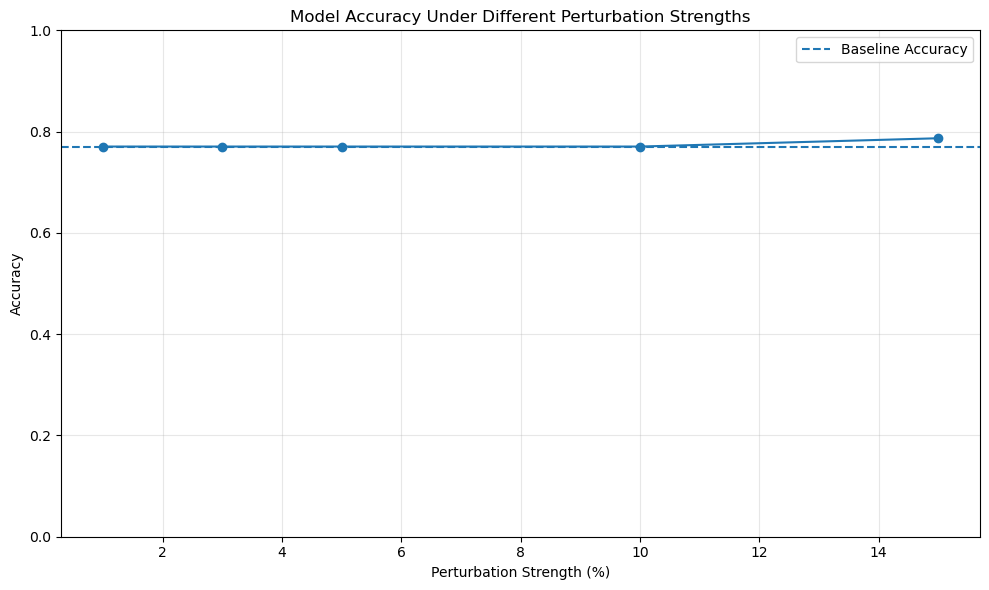

In [13]:
plt.figure(figsize=(10, 6))

plt.plot(
    strength_df["Perturbation Strength"] * 100,
    strength_df["Accuracy"],
    marker="o"
)

plt.axhline(
    baseline_accuracy,
    linestyle="--",
    label="Baseline Accuracy"
)

plt.title("Model Accuracy Under Different Perturbation Strengths")
plt.xlabel("Perturbation Strength (%)")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

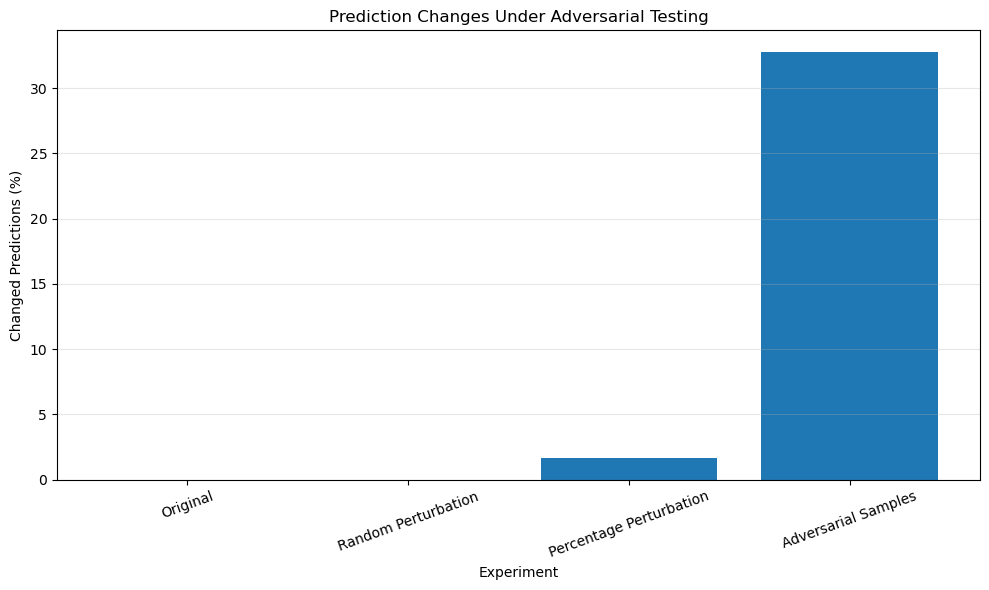

In [14]:
plt.figure(figsize=(10, 6))

plt.bar(
    change_df["Experiment"],
    change_df["Prediction Change (%)"]
)

plt.title("Prediction Changes Under Adversarial Testing")
plt.xlabel("Experiment")
plt.ylabel("Changed Predictions (%)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
robustness_score = 100 - change_df[
    "Prediction Change (%)"
]

robustness_summary = pd.DataFrame({

    "Experiment": change_df["Experiment"],

    "Prediction Change (%)": change_df[
        "Prediction Change (%)"
    ],

    "Robustness Score (%)": robustness_score

})

display(robustness_summary)

,Experiment,Prediction Change (%),Robustness Score (%)
0,Original,0.000000,100.000000
1,Random Perturbation,0.000000,100.000000
2,Percentage Perturbation,1.639344,98.360656
3,Adversarial Samples,32.786885,67.213115


In [16]:
vulnerability_results = []

for feature in top_features:

    X_changed = X_test_imputed.copy()

    feature_std = X_train_imputed[feature].std()

    X_changed[feature] = (
        X_changed[feature] + 0.10 * feature_std
    )

    predictions = model.predict(X_changed)

    changed = np.sum(
        predictions != original_predictions
    )

    vulnerability_results.append({

        "Feature": feature,

        "Changed Predictions": changed,

        "Change Percentage": (
            changed / len(original_predictions)
        ) * 100
    })


vulnerability_df = pd.DataFrame(
    vulnerability_results
).sort_values(
    by="Change Percentage",
    ascending=False
)

display(vulnerability_df)

,Feature,Changed Predictions,Change Percentage
1,thalach,1,1.639344
0,cp,0,0.000000
2,ca,0,0.000000
3,thal,0,0.000000
4,oldpeak,0,0.000000


In [17]:
robustness_df.to_csv(
    "adversarial_robustness_results.csv",
    index=False
)

change_df.to_csv(
    "adversarial_prediction_changes.csv",
    index=False
)

strength_df.to_csv(
    "perturbation_strength_results.csv",
    index=False
)

robustness_summary.to_csv(
    "model_robustness_summary.csv",
    index=False
)

vulnerability_df.to_csv(
    "feature_vulnerability_results.csv",
    index=False
)

print("Adversarial testing results exported successfully.")

Adversarial testing results exported successfully.


In [18]:
report = []

report.append("# Adversarial Testing and Model Robustness Report\n")

report.append("## Objective\n")
report.append(
    "The experiment evaluates how small input modifications "
    "affect the predictions of the heart disease classification model.\n"
)

report.append("## Testing Methods\n")
report.append(
    "1. Random numerical perturbations.\n"
    "2. Percentage-based feature modifications.\n"
    "3. Manually designed opposite-class median perturbations.\n"
    "4. Different perturbation strengths.\n"
    "5. Individual feature vulnerability testing.\n"
)

report.append("\n## Baseline Performance\n")
report.append(
    f"Accuracy: {baseline_accuracy:.4f}\n"
    f"F1 Score: {baseline_f1:.4f}\n"
)

report.append("\n## Robustness Results\n")
report.append(robustness_df.to_string(index=False))

report.append("\n## Perturbation Strength Results\n")
report.append(strength_df.to_string(index=False))

report.append("\n## Feature Vulnerability\n")
report.append(vulnerability_df.to_string(index=False))

report.append("\n## Conclusion\n")
report.append(
    "The experiments quantify the sensitivity of the model to "
    "controlled feature modifications. A high prediction-change "
    "percentage indicates greater sensitivity, while a high robustness "
    "score indicates that more predictions remained unchanged. "
    "Synthetic perturbations may produce medically unrealistic records, "
    "so these results should be interpreted as stress-test findings "
    "rather than evidence of real-world clinical robustness.\n"
)

with open(
    "adversarial_testing_report.md",
    "w",
    encoding="utf-8"
) as file:

    file.write("\n".join(report))

print("Adversarial testing report generated successfully.")

Adversarial testing report generated successfully.
